# Player Scouting & Similarity Tool
Cluster players into roles, find "the next [player]" and (later) cheaper replacements.

Data: FBref-style 2024-25 player stats, Big 5 leagues.

## 1. Upload the 3 files
Select all three at once: the FBref stats CSV (`players_data-2024_2025...csv`), `players.csv` and `player_valuations.csv` (the Transfermarkt files).

In [1]:
from google.colab import files
uploaded = files.upload()

FBREF_PATH   = next(k for k in uploaded if k.startswith("players_data"))
PLAYERS_PATH = next(k for k in uploaded if k.startswith("players") and not k.startswith("players_data"))
VALS_PATH    = next(k for k in uploaded if k.startswith("player_valuations"))
print(FBREF_PATH, PLAYERS_PATH, VALS_PATH, sep="\n")

Saving players.csv to players.csv
Saving players_data-2024_2025 (2).csv to players_data-2024_2025 (2).csv
Saving player_valuations.csv to player_valuations.csv
players_data-2024_2025 (2).csv
players.csv
player_valuations.csv


In [2]:
%pip -q install rapidfuzz

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.2/3.2 MB 32.9 MB/s eta 0:00:00


## 2. Load and clean

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.metrics.pairwise import cosine_similarity

MIN_MINUTES = 900

# raw column in CSV -> short feature name (all converted to per-90)
COUNT_COLS = {
    "npxG": "npxG", "xAG": "xAG", "Sh": "Sh", "SoT": "SoT",
    "KP": "KP", "SCA": "SCA", "PPA": "PPA", "CrsPA": "CrsPA",
    "PrgP": "PrgP", "PrgC": "PrgC", "PrgR": "PrgR",
    "Cmp": "Cmp", "Succ": "Succ", "Carries": "Carries",
    "Touches": "Touches", "Att Pen": "AttPen", "Def Pen": "DefPen",
    "CPA": "CPA", "Crs": "Crs", "TB": "TB", "Sw": "Sw",
    "Tkl": "Tkl", "Int": "Int", "Blocks_stats_defense": "Blk",
    "Clr": "Clr", "Recov": "Recov", "Won": "AerialWon", "Fls": "Fls",
    "Fld": "Fld", "Mis": "Mis", "Dis": "Dis", "Rec": "Rec",
    "PrgDist": "PrgDist",
}

def load_clean(path, min_minutes=MIN_MINUTES):
    df = pd.read_csv(path)
    df = df[~df["Pos"].eq("GK")].copy()                      # outfield only
    df["PosGroup"] = df["Pos"].str.split(",").str[0]         # primary position

    num_cols = ["Min"] + list(COUNT_COLS)
    df[num_cols] = df[num_cols].apply(pd.to_numeric, errors="coerce").fillna(0)

    # players who moved clubs mid-season have 2 rows -> merge
    df = df.sort_values("Min", ascending=False)
    meta = df.drop_duplicates(["Player", "Born"])[
        ["Player", "Born", "Nation", "Pos", "PosGroup", "Squad", "Comp", "Age"]]
    agg = df.groupby(["Player", "Born"], as_index=False)[num_cols].sum()
    d = meta.merge(agg, on=["Player", "Born"])

    d = d[d["Min"] >= min_minutes].copy()
    d["90s"] = d["Min"] / 90
    d["Comp"] = d["Comp"].str.split(" ", n=1).str[1]
    return d.reset_index(drop=True)

def build_features(d):
    f = pd.DataFrame(index=d.index)
    for raw, name in COUNT_COLS.items():
        f[name + "_p90"] = d[raw] / d["90s"]
    return f

d = load_clean(FBREF_PATH)
f = build_features(d)
print(d.shape)
print(d["PosGroup"].value_counts())
d.head()

(1457, 43)
PosGroup
DF    617
MF    494
FW    346
Name: count, dtype: int64


,Player,Born,Nation,Pos,PosGroup,Squad,Comp,Age,Min,npxG,...,Clr,Recov,Won,Fls,Fld,Mis,Dis,Rec,PrgDist,90s
0,Federico Baschirotto,1996.0,it ITA,DF,DF,Lecce,Serie A,27.0,3420,1.2,...,237,93,104,31,0,13,1,1157,9707,38.000000
1,Nathan Collins,2001.0,ie IRL,DF,DF,Brentford,Premier League,23.0,3420,2.5,...,226,162,117,29,2,20,8,1490,10799,38.000000
2,Obite N'Dicka,1999.0,ci CIV,DF,DF,Roma,Serie A,24.0,3420,1.0,...,150,134,61,37,0,20,3,2065,14137,38.000000
3,Bryan Mbeumo,1999.0,cm CMR,FW,FW,Brentford,Premier League,24.0,3414,7.5,...,55,156,34,25,4,106,47,1204,4325,37.933333
4,Amir Rrahmani,1994.0,xk KVX,DF,DF,Napoli,Serie A,30.0,3406,2.9,...,179,135,124,42,0,9,6,2254,17211,37.844444


## 3. Pick the number of roles (silhouette score)
Higher is better, but also check that the clusters make football sense (next section).

In [4]:
for pos in ["DF", "MF", "FW"]:
    idx = d.index[d["PosGroup"] == pos]
    Z = PCA(n_components=0.90, random_state=0).fit_transform(
        StandardScaler().fit_transform(f.loc[idx]))
    scores = {k: round(silhouette_score(
        Z, KMeans(k, n_init=20, random_state=0).fit_predict(Z)), 3) for k in range(3, 8)}
    print(pos, len(idx), scores)

DF 617 {3: np.float64(0.204), 4: np.float64(0.197), 5: np.float64(0.177), 6: np.float64(0.122), 7: np.float64(0.117)}
MF 494 {3: np.float64(0.232), 4: np.float64(0.195), 5: np.float64(0.172), 6: np.float64(0.13), 7: np.float64(0.125)}
FW 346 {3: np.float64(0.201), 4: np.float64(0.147), 5: np.float64(0.139), 6: np.float64(0.138), 7: np.float64(0.125)}


## 4. Cluster roles and inspect them

In [5]:
K = {"DF": 4, "MF": 4, "FW": 4}      # change after looking at section 3
d["role_id"] = -1
for pos, idx in d.groupby("PosGroup").groups.items():
    if pos not in K:
        continue
    Z = PCA(n_components=0.90, random_state=0).fit_transform(
        StandardScaler().fit_transform(f.loc[idx]))
    d.loc[idx, "role_id"] = KMeans(K[pos], n_init=20, random_state=0).fit_predict(Z)

show = ["npxG","xAG","Sh","KP","PrgP","PrgC","Succ","Touches","AttPen",
        "Tkl","Int","Clr","AerialWon","Recov","Crs"]
show = [s + "_p90" for s in show]

for pos in ["DF", "MF", "FW"]:
    sub = d[d.PosGroup == pos]
    fz = (f.loc[sub.index] - f.loc[sub.index].mean()) / f.loc[sub.index].std()
    prof = fz.groupby(sub["role_id"])[show].mean()
    print(f"\n=== {pos} ===")
    for r in prof.index:
        top = prof.loc[r].sort_values(ascending=False)
        ex = sub[sub.role_id == r].sort_values("Min", ascending=False).Player.head(6).tolist()
        print(f"role {r} (n={(sub.role_id==r).sum()}) HIGH:",
              ", ".join(top.index[:4].str.replace("_p90", "")),
              "| LOW:", ", ".join(top.index[-3:].str.replace("_p90", "")))
        print("   e.g.", ex)


=== DF ===
role 0 (n=87) HIGH: xAG, AttPen, KP, PrgC | LOW: Int, AerialWon, Clr
   e.g. ['Daniel Muñoz', 'Antonee Robinson', 'Rayan Aït-Nouri', 'Keane Lewis-Potter', 'Andrei Ratiu', 'Dodô']
role 1 (n=237) HIGH: Clr, AerialWon, Int, npxG | LOW: Crs, KP, PrgC
   e.g. ['Federico Baschirotto', 'Nathan Collins', 'Max Kilman', 'Nikola Milenković', 'Dan Burn', 'Cristhian Mosquera']
role 2 (n=183) HIGH: Crs, KP, PrgC, Tkl | LOW: Touches, Clr, AerialWon
   e.g. ['Milos Kerkez', 'Giovanni Di Lorenzo', 'Emmanuel Gyasi', 'Angeliño', 'Jackson Tchatchoua', 'Aaron Wan-Bissaka']
role 3 (n=110) HIGH: Touches, PrgP, Recov, AerialWon | LOW: xAG, KP, Crs
   e.g. ["Obite N'Dicka", 'Amir Rrahmani', 'Virgil van Dijk', 'Florian Lejeune', 'Joško Gvardiol', 'Levi Colwill']

=== MF ===
role 0 (n=128) HIGH: AttPen, Succ, npxG, Sh | LOW: Int, PrgP, Touches
   e.g. ['Simon Sohm', 'Aimar Oroz', 'Scott McTominay', 'Mateus Fernandes', 'Luis Rioja', 'Morgan Gibbs-White']
role 1 (n=206) HIGH: Clr, Int, Tkl, AerialWon |

### Name your roles
Look at the output above and give each cluster a football name.

In [6]:
ROLE_NAMES = {
    ("DF", 0): "Attacking full-back",
    ("DF", 1): "Aerial centre-back",
    ("DF", 2): "Crossing full-back",
    ("DF", 3): "Ball-playing centre-back",
    ("MF", 0): "Defensive midfielder",
    ("MF", 1): "Box-crashing 8",
    ("MF", 2): "Deep playmaker",
    ("MF", 3): "Attacking creator",
    ("FW", 0): "Penalty-box striker",
    ("FW", 1): "Hard-working wide forward",
    ("FW", 2): "Creative wide forward",
    ("FW", 3): "Target man",
}
d["role"] = [ROLE_NAMES.get((p, r), f"{p}-{r}") for p, r in zip(d.PosGroup, d.role_id)]
d[["Player", "Squad", "Comp", "Age", "role"]].sample(8, random_state=1)

,Player,Squad,Comp,Age,role
1162,Antoine Hainaut,Parma,Serie A,22.0,Crossing full-back
111,Iglesias,Getafe,La Liga,26.0,Crossing full-back
1272,Maxence Caqueret,Como,Serie A,24.0,Deep playmaker
1146,Mika Biereth,Monaco,Ligue 1,21.0,Penalty-box striker
368,Marvin Ducksch,Werder Bremen,Bundesliga,30.0,Hard-working wide forward
37,Jay Idzes,Venezia,Serie A,24.0,Aerial centre-back
1127,Assane Diao,Como,Serie A,18.0,Hard-working wide forward
993,Giovani Lo Celso,Betis,La Liga,28.0,Attacking creator


## 4b. Add Transfermarkt market values
Matches each FBref player to Transfermarkt by normalized name + birth year, then falls back to fuzzy name matching and finally surname + birth year + club similarity.

In [7]:
import re, unicodedata
from rapidfuzz import fuzz

def norm(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode().lower()
    return re.sub(r"\s+", " ", re.sub(r"[^a-z ]", " ", s)).strip()

TM_COLS = ["player_id", "name", "sub_position", "foot", "height_in_cm",
           "contract_expiration_date", "current_club_name", "last_season"]

def add_market_values(d, players_path, vals_path):
    tm = pd.read_csv(players_path)
    tm["born"] = pd.to_datetime(tm["date_of_birth"], errors="coerce").dt.year
    tm = tm[tm["last_season"] >= 2024].copy()          # recently active players only
    tm["key"] = tm["name"].map(norm)
    tm["club_key"] = tm["current_club_name"].map(norm)
    tm["tokens"] = tm["key"].str.split().map(set)

    d = d.copy()
    d["key"] = d["Player"].map(norm)
    extra = pd.DataFrame(index=d.index, columns=TM_COLS + ["match_type", "club_sim"], dtype=object)

    # pass 1: exact normalized name + birth year
    tmu = tm.sort_values("last_season", ascending=False).drop_duplicates(["key", "born"])
    ex = (d[["key", "Born"]].reset_index()
            .merge(tmu, left_on=["key", "Born"], right_on=["key", "born"], how="left")
            .set_index("index"))
    hit = ex["player_id"].notna()
    extra.loc[hit[hit].index, TM_COLS] = ex.loc[hit, TM_COLS].values
    extra.loc[hit[hit].index, "match_type"] = "exact"

    # pass 2: fuzzy name, same birth year
    for i in extra.index[extra["player_id"].isna()]:
        cand = tm[tm["born"] == d.loc[i, "Born"]]
        if cand.empty:
            continue
        best = process_extract(d.loc[i, "key"], cand["key"].tolist())
        if best:
            row = cand.iloc[best]
            extra.loc[i, TM_COLS] = row[TM_COLS].values
            extra.loc[i, "match_type"] = "fuzzy"

    # pass 3: surname + birth year (+ club similarity to choose between candidates)
    for i in extra.index[extra["player_id"].isna()]:
        toks = d.loc[i, "key"].split()
        if not toks:
            continue
        cand = tm[(tm["born"] == d.loc[i, "Born"]) & tm["tokens"].map(lambda t: toks[-1] in t)]
        if cand.empty:
            continue
        sq = norm(d.loc[i, "Squad"])
        cand = cand.assign(cs=cand["club_key"].map(lambda c: fuzz.partial_ratio(sq, c)))
        if len(cand) == 1 or cand["cs"].max() >= 70:
            row = cand.sort_values("cs", ascending=False).iloc[0]
            extra.loc[i, TM_COLS] = row[TM_COLS].values
            extra.loc[i, "match_type"] = "surname+club"
            extra.loc[i, "club_sim"] = row["cs"]

    # valuations: latest, and as of the end of the 2024-25 season
    v = pd.read_csv(vals_path, usecols=["player_id", "date", "market_value_in_eur"],
                    parse_dates=["date"]).sort_values("date")
    latest = v.groupby("player_id").tail(1).set_index("player_id")
    end = v[v["date"] <= "2025-06-30"].groupby("player_id").tail(1).set_index("player_id")
    pid = extra["player_id"].astype(float)
    d["tm_name"] = extra["name"]
    d["tm_club"] = extra["current_club_name"]
    d["tm_position"] = extra["sub_position"]
    d["foot"] = extra["foot"]
    d["height_in_cm"] = pd.to_numeric(extra["height_in_cm"], errors="coerce")
    d["contract_expiry"] = pd.to_datetime(extra["contract_expiration_date"], errors="coerce")
    d["value_latest"] = pid.map(latest["market_value_in_eur"])
    d["value_date"] = pid.map(latest["date"])
    d["value_end2425"] = pid.map(end["market_value_in_eur"])
    d["match_type"] = extra["match_type"].fillna("none")
    d["club_sim"] = pd.to_numeric(extra["club_sim"], errors="coerce")
    return d

def process_extract(key, choices, threshold=88):
    """index of best fuzzy match above threshold, else None"""
    from rapidfuzz import process
    best = process.extractOne(key, choices, scorer=fuzz.token_sort_ratio)
    return best[2] if best and best[1] >= threshold else None

d = add_market_values(d, PLAYERS_PATH, VALS_PATH)
print(d["match_type"].value_counts())
print("players with a market value:", d["value_latest"].notna().sum(), "of", len(d))

match_type
exact           1357
surname+club      45
fuzzy             29
none              26
Name: count, dtype: int64
players with a market value: 1425 of 1457


### Check the risky matches
The `surname+club` matches are the ones most likely to be wrong (e.g. when a player moved clubs). Eyeball this list and drop any that look wrong.

In [8]:
review = d[(d.match_type == "surname+club")][["Player", "Squad", "tm_name", "tm_club", "Born", "club_sim"]]
review.sort_values("club_sim")

,Player,Squad,tm_name,tm_club,Born,club_sim
684,Fabián Ruiz Peña,Paris S-G,Alexis Peña,Club Necaxa,1996.0,20.000000
387,Valentín Castellanos,Lazio,Taty Castellanos,West Ham United,1998.0,22.222222
190,Alexsandro Ribeiro,Lille,Tomás Ribeiro,Vitória Guimarães SC,1999.0,28.571429
534,Isaac Palazón Camacho,Rayo Vallecano,João Camacho,Fatih Karagümrük,1994.0,33.333333
445,Douglas,Nantes,Douglas Augusto,FK Krasnodar,1997.0,36.363636
1057,Alfon,Celta Vigo,Alfon González,Villarreal CF,1999.0,37.500000
1245,Faustino Anjorin,Empoli,Tino Anjorin,Torino FC,2001.0,40.000000
302,Kiké,Alavés,Kike García,RCD Espanyol Barcelona,1989.0,40.000000
581,Hamed Junior Traorè,Auxerre,Hamed Traoré,Olympique Marseille,2000.0,42.857143
1148,Leo Skiri Østigård,Rennes,Leo Østigård,Genoa CFC,1999.0,44.444444


In [9]:
# To remove a wrong match, list the FBref player names here; their value columns are blanked.
BAD_MATCHES = []        # e.g. ["Alexsandro Ribeiro", "Isaac Palazón Camacho"]
val_cols = ["tm_name","tm_club","tm_position","foot","height_in_cm","contract_expiry",
            "value_latest","value_date","value_end2425"]
d.loc[d["Player"].isin(BAD_MATCHES), val_cols] = np.nan
d[["Player","Squad","Age","role","value_latest","contract_expiry"]].sort_values(
    "value_latest", ascending=False).head(10)

,Player,Squad,Age,role,value_latest,contract_expiry
124,Lamine Yamal,Barcelona,17.0,Creative wide forward,200000000.0,2031-06-30
174,Erling Haaland,Manchester City,24.0,Penalty-box striker,200000000.0,2034-06-30
109,Kylian Mbappé,Real Madrid,25.0,Creative wide forward,180000000.0,2029-06-30
419,Michael Olise,Bayern Munich,22.0,Creative wide forward,150000000.0,2029-06-30
116,Pedri,Barcelona,21.0,Deep playmaker,150000000.0,2030-06-30
609,Vitinha,Paris S-G,24.0,Deep playmaker,140000000.0,2029-06-30
482,Vinicius Júnior,Real Madrid,24.0,Creative wide forward,140000000.0,2027-06-30
733,João Neves,Paris S-G,19.0,Deep playmaker,140000000.0,2029-06-30
1184,Khvicha Kvaratskhelia,Napoli,23.0,Creative wide forward,140000000.0,2029-06-30
329,Jude Bellingham,Real Madrid,21.0,Attacking creator,130000000.0,2029-06-30


## 5. Find similar players

In [10]:
def find_similar(player, n=8, same_pos=True, max_age=None, leagues=None, same_role=False):
    """Most similar players to `player` (cosine similarity in PCA space)."""
    match = d.index[d["Player"].str.lower() == player.lower()]
    if len(match) == 0:
        raise ValueError(f"{player!r} not found (or under {MIN_MINUTES} minutes)")
    i = match[0]
    pool = d.index[d["PosGroup"] == d.loc[i, "PosGroup"]] if same_pos else d.index
    Z = PCA(n_components=0.90, random_state=0).fit_transform(
        StandardScaler().fit_transform(f.loc[pool]))
    sim = cosine_similarity(Z[list(pool).index(i)].reshape(1, -1), Z)[0]

    out = d.loc[pool, ["Player", "Squad", "Comp", "Age", "role"]].copy()
    out["similarity"] = sim.round(3)
    out = out.drop(index=i)
    if same_role:
        out = out[out["role"] == d.loc[i, "role"]]
    if max_age:
        out = out[out["Age"] <= max_age]
    if leagues:
        out = out[out["Comp"].isin(leagues)]
    return out.sort_values("similarity", ascending=False).head(n)

find_similar("Cole Palmer")

,Player,Squad,Comp,Age,role,similarity
779,Phil Foden,Manchester City,Premier League,24.0,Attacking creator,0.956
1445,Marco Asensio,Aston Villa,Premier League,28.0,Attacking creator,0.908
258,Matheus Cunha,Wolves,Premier League,25.0,Attacking creator,0.899
796,Hákon Arnar Haraldsson,Lille,Ligue 1,21.0,Attacking creator,0.891
1126,Fermin López,Barcelona,La Liga,21.0,Attacking creator,0.886
837,Kevin De Bruyne,Manchester City,Premier League,33.0,Attacking creator,0.878
266,Eberechi Eze,Crystal Palace,Premier League,26.0,Attacking creator,0.876
321,Dilane Bakwa,Strasbourg,Ligue 1,21.0,Attacking creator,0.867


In [11]:
# "next [player]": young players only
find_similar("Lamine Yamal", max_age=23, n=10)

,Player,Squad,Comp,Age,role,similarity
1184,Khvicha Kvaratskhelia,Napoli,Serie A,23.0,Creative wide forward,0.922
419,Michael Olise,Bayern Munich,Bundesliga,22.0,Creative wide forward,0.899
789,Sávio,Manchester City,Premier League,20.0,Creative wide forward,0.869
814,Désiré Doué,Paris S-G,Ligue 1,19.0,Creative wide forward,0.846
375,Maghnes Akliouche,Monaco,Ligue 1,22.0,Creative wide forward,0.831
610,Rayan Cherki,Lyon,Ligue 1,20.0,Creative wide forward,0.830
522,Bradley Barcola,Paris S-G,Ligue 1,21.0,Creative wide forward,0.801
1099,Osame Sahraoui,Lille,Ligue 1,23.0,Creative wide forward,0.781
969,Jeremy Doku,Manchester City,Premier League,22.0,Creative wide forward,0.769
817,Bukayo Saka,Arsenal,Premier League,22.0,Creative wide forward,0.767


In [12]:
# a few sanity checks
for p in ["Virgil van Dijk", "Vitinha", "Erling Haaland"]:
    print("\n>>", p)
    print(find_similar(p, n=5).to_string(index=False))


>> Virgil van Dijk
         Player         Squad       Comp  Age                     role  similarity
 Stefan de Vrij         Inter    Serie A 32.0 Ball-playing centre-back       0.930
Lilian Brassier        Rennes    Ligue 1 24.0 Ball-playing centre-back       0.928
  Julian Chabot     Stuttgart Bundesliga 26.0 Ball-playing centre-back       0.901
  Amir Rrahmani        Napoli    Serie A 30.0 Ball-playing centre-back       0.893
      Eric Dier Bayern Munich Bundesliga 30.0 Ball-playing centre-back       0.893

>> Vitinha
          Player         Squad       Comp  Age           role  similarity
  Nicolò Barella         Inter    Serie A 27.0 Deep playmaker       0.842
           Pedri     Barcelona    La Liga 21.0 Deep playmaker       0.841
      João Neves     Paris S-G    Ligue 1 19.0 Deep playmaker       0.818
  Joshua Kimmich Bayern Munich Bundesliga 29.0 Deep playmaker       0.804
Fabián Ruiz Peña     Paris S-G    Ligue 1 28.0 Deep playmaker       0.804

>> Erling Haaland
       

## 6. Radar chart comparison

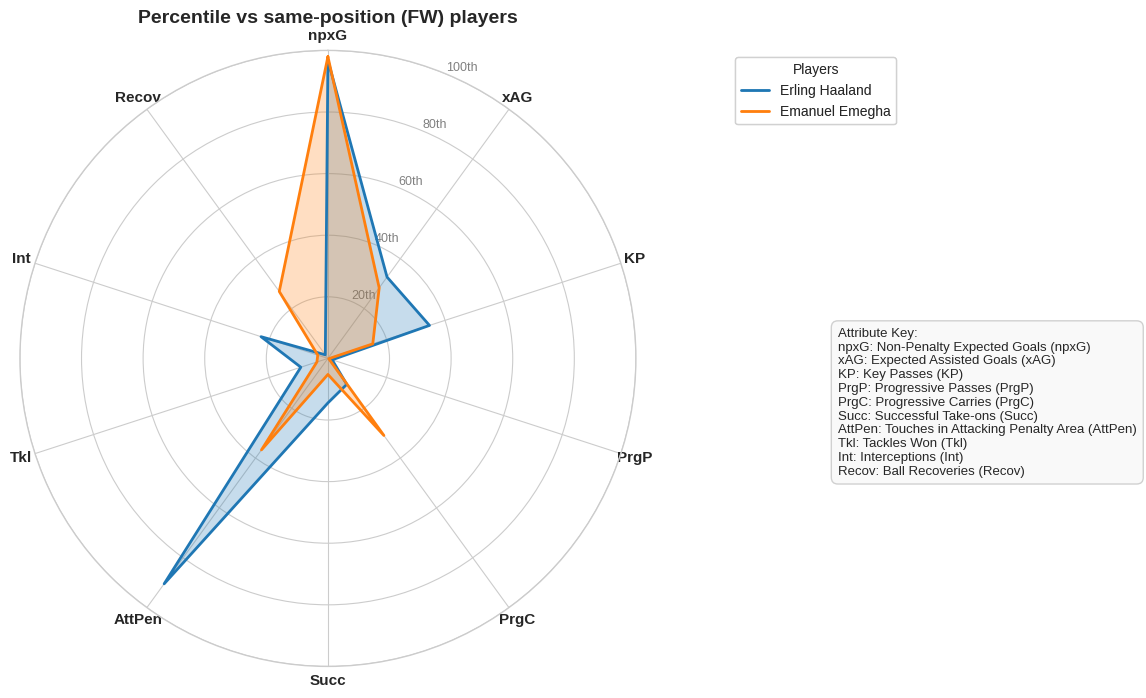

In [23]:
def radar(players, features=None):
    # Full descriptions for the legend mapping
    desc_map = {
        "npxG_p90": "Non-Penalty Expected Goals (npxG)",
        "xAG_p90": "Expected Assisted Goals (xAG)",
        "KP_p90": "Key Passes (KP)",
        "PrgP_p90": "Progressive Passes (PrgP)",
        "PrgC_p90": "Progressive Carries (PrgC)",
        "Succ_p90": "Successful Take-ons (Succ)",
        "AttPen_p90": "Touches in Attacking Penalty Area (AttPen)",
        "Tkl_p90": "Tackles Won (Tkl)",
        "Int_p90": "Interceptions (Int)",
        "Recov_p90": "Ball Recoveries (Recov)"
    }

    features = features or ["npxG_p90","xAG_p90","KP_p90","PrgP_p90","PrgC_p90",
                            "Succ_p90","AttPen_p90","Tkl_p90","Int_p90","Recov_p90"]

    rows = d[d["Player"].isin(players)]
    pos = rows["PosGroup"].iloc[0]
    pool = f.loc[d.index[d.PosGroup == pos], features]
    pct = pool.rank(pct=True)                      # percentile within position

    angles = np.linspace(0, 2*np.pi, len(features), endpoint=False).tolist()
    angles += angles[:1]

    # Style configuration
    plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
    fig, ax = plt.subplots(figsize=(8, 8), subplot_kw=dict(polar=True))

    # Draw one axe per variable and add labels
    ax.set_theta_offset(np.pi / 2)
    ax.set_theta_direction(-1)

    for idx, r in rows.iterrows():
        vals = pct.loc[idx].tolist()
        vals += vals[:1]
        ax.plot(angles, vals, linewidth=2, linestyle='solid', label=r["Player"])
        ax.fill(angles, vals, alpha=0.25)

    ax.set_xticks(angles[:-1])
    ax.set_xticklabels([x.replace("_p90", "") for x in features], fontsize=11, fontweight='bold')

    # Y-ticks and gridlines styling
    ax.set_ylim(0, 1)
    ax.set_rgrids([0.2, 0.4, 0.6, 0.8, 1.0], labels=["20th", "40th", "60th", "80th", "100th"], color="gray", size=9)

    # Add a custom legend explaining what each attribute is
    attr_legend_text = "\n".join([f"{k.replace('_p90', '')}: {v}" for k, v in desc_map.items() if k in features])

    # Primary Player Legend
    player_legend = ax.legend(loc="upper left", bbox_to_anchor=(1.15, 1.0), title="Players", frameon=True, fontsize=10)
    ax.add_artist(player_legend)

    # Attribute glossary legend text block
    fig.text(1.15, 0.35, f"Attribute Key:\n{attr_legend_text}", fontsize=9.5,
             bbox=dict(boxstyle="round,pad=0.5", facecolor="#f9f9f9", edgecolor="#cccccc", alpha=0.9))

    plt.title(f"Percentile vs same-position ({pos}) players", fontsize=14, fontweight='bold', pad=20)
    plt.show()

radar(["Erling Haaland", "Emanuel Emegha"])

## 7. Cheaper replacements
Similar players who cost much less. `value_latest` = most recent Transfermarkt value; use `value_col="value_end2425"` to compare at end-of-2024-25 prices instead.

In [18]:
def find_cheaper(player, n=10, max_value_ratio=0.5, min_similarity=0.80, max_age=None,
                 leagues=None, same_role=False, value_col="value_latest"):
    """Players similar to `player` whose market value is <= max_value_ratio x theirs."""
    i = d.index[d["Player"].str.lower() == player.lower()]
    if len(i) == 0:
        raise ValueError(f"{player!r} not found")
    target = d.loc[i[0], value_col]
    if pd.isna(target):
        raise ValueError(f"No market value for {player}")
    c = find_similar(player, n=len(d), max_age=max_age, leagues=leagues, same_role=same_role)
    c = c.join(d[[value_col, "contract_expiry", "foot", "height_in_cm"]])
    c = c[(c["similarity"] >= min_similarity) & (c[value_col] <= max_value_ratio * target)].copy()
    c["value_EURm"] = (c[value_col] / 1e6).round(1)
    c["saving_%"] = ((1 - c[value_col] / target) * 100).round(0)
    c["contract_to"] = c["contract_expiry"].dt.strftime("%Y-%m")
    print(f"{player}: EUR {target/1e6:.0f}m ({value_col})")
    cols = ["Player", "Squad", "Comp", "Age", "role", "similarity", "value_EURm", "saving_%", "contract_to"]
    return c.sort_values("similarity", ascending=False)[cols].head(n)

find_cheaper("Erling Haaland")

Erling Haaland: EUR 200m (value_latest)


,Player,Squad,Comp,Age,role,similarity,value_EURm,saving_%,contract_to
728,Ermedin Demirović,Stuttgart,Bundesliga,26.0,Penalty-box striker,0.954,22.0,89.0,2028-06
256,Ollie Watkins,Aston Villa,Premier League,28.0,Penalty-box striker,0.929,25.0,88.0,2028-06
209,Robert Lewandowski,Barcelona,La Liga,35.0,Penalty-box striker,0.921,7.0,96.0,NaN
458,Emanuel Emegha,Strasbourg,Ligue 1,21.0,Target man,0.905,25.0,88.0,2033-06
848,Patrik Schick,Leverkusen,Bundesliga,28.0,Penalty-box striker,0.897,18.0,91.0,2030-06
771,Dušan Vlahović,Juventus,Serie A,24.0,Penalty-box striker,0.894,35.0,82.0,NaN
387,Valentín Castellanos,Lazio,Serie A,25.0,Penalty-box striker,0.880,28.0,86.0,2030-06
104,Yoane Wissa,Brentford,Premier League,27.0,Penalty-box striker,0.872,25.0,88.0,2029-06
1289,Gonçalo Ramos,Paris S-G,Ligue 1,23.0,Penalty-box striker,0.863,30.0,85.0,2031-06
1317,Myron Boadu,Bochum,Bundesliga,23.0,Penalty-box striker,0.856,4.0,98.0,NaN


In [15]:
# young + cheap alternatives to an expensive midfielder, any league
find_cheaper("Vitinha", max_age=24, max_value_ratio=0.4, min_similarity=0.75)

Vitinha: EUR 140m (value_latest)


,Player,Squad,Comp,Age,role,similarity,value_EURm,saving_%,contract_to
1388,Thiago Almada,Lyon,Ligue 1,23.0,Deep playmaker,0.775,15.0,89.0,2030-06


## Next steps
- Improve features (normalize by team possession, split wingers from inside forwards)
- Add a value-for-money score and filter by contract expiry (players with 1 year left are usually cheaper)
- Wrap in a Streamlit app